# 03 — Engenharia de Atributos, Modelo LightGBM e Fila Semanal

Este notebook documenta e reproduz a avaliação oficial do modelo **LightGBM (v1)** do FraudRadar
PLD, utilizando exclusivamente os módulos de `src/fraudradar/` (`features/history.py` e
`model/`) e o artefato oficial em `models/lightgbm_v1.txt` / `models/lightgbm_v1.json`
(referência em `docs/model.md`).

**Decisões metodológicas principais:**
1. **Sem vazamento futuro:** todas as 26 variáveis de `compute_features` consideram apenas
   transações estritamente anteriores ao horário da transação atual.
2. **Tratamento do CAIXA (`CASH_ACCOUNT = -1`):** em depósitos e saques em espécie, o SAML-D cria
   contas sintéticas descartáveis apenas nas transações normais (o que vazava a resposta em 28% das
   lavagens). Substituir o lado externo pelo `CASH_ACCOUNT` remove esse atalho.
3. **Exclusão de atalhos (`EXCLUDED_FEATURES`):** país, moeda e hora ficam fora do modelo (restam
   **21 variáveis**).
4. **Divisão temporal rígida:** treino até `2023-04-23`, validação de `2023-04-24` a `2023-05-21`
   (4 semanas) e teste fora da amostra de `2023-05-22` a `2023-08-23` (14 semanas).


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import precision_recall_curve

from fraudradar.config import ROOT_DIR
from fraudradar.data.saml_d import load_csv
from fraudradar.features.history import CASH_ACCOUNT, account_profile, compute_features
from fraudradar.model.evaluation import (
    account_weeks,
    evaluate,
    false_positive_by_group,
    queue_with_cut,
)
from fraudradar.model.segments import assign_segments
from fraudradar.model.training import (
    EXCLUDED_FEATURES,
    LIGHTGBM_PARAMS,
    OFFICIAL_SPLIT,
    build_training_data,
    explain,
    load_model,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

print("Divisão temporal oficial:", OFFICIAL_SPLIT)
print("Conta CAIXA sintética:", CASH_ACCOUNT)
print("Variáveis excluídas (atalhos):", EXCLUDED_FEATURES)
print("Hiperparâmetros oficiais LightGBM:", LIGHTGBM_PARAMS)

Divisão temporal oficial: Split(train_end='2023-05-21', validation_start='2023-04-24')
Conta CAIXA sintética: -1
Variáveis excluídas (atalhos): ('sender_country', 'receiver_country', 'cross_border', 'currency_mismatch', 'hour')
Hiperparâmetros oficiais LightGBM: {'n_estimators': 5000, 'learning_rate': 0.05, 'num_leaves': 15, 'min_child_samples': 1000, 'reg_lambda': 10, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8}


## 1. Carga, cálculo das variáveis e montagem dos cortes temporais

Calculamos as 26 variáveis com `compute_features` e montamos `TrainingData` e `truth` com
`build_training_data` (que isola o gabarito em `truth`).


In [2]:
tx, gt = load_csv(ROOT_DIR / "data" / "SAML-D.csv")
features = compute_features(tx)
data, truth = build_training_data(tx, gt, features)
del features

split_summary = pd.DataFrame(
    [
        {
            "parte": nome,
            "transacoes": int(mask.sum()),
            "lavagens": int((mask & (truth["y"].to_numpy() == 1)).sum()),
            "taxa_lavagem_pct": float((truth["y"].to_numpy()[mask] == 1).mean() * 100),
            "inicio": pd.Timestamp(truth.loc[mask, "week"].min()).date(),
            "fim": pd.Timestamp(truth.loc[mask, "week"].max()).date(),
        }
        for nome, mask in [
            ("Treino", data.train),
            ("Validação", data.validation),
            ("Teste (out-of-sample)", data.test),
        ]
    ]
)
display(split_summary.round(4))

,parte,transacoes,lavagens,taxa_lavagem_pct,inicio,fim
0,Treino,5916469,6023,0.1018,2022-10-03,2023-04-17
1,Validação,831036,810,0.0975,2023-04-24,2023-05-15
2,Teste (out-of-sample),2757347,3040,0.1103,2023-05-22,2023-08-21


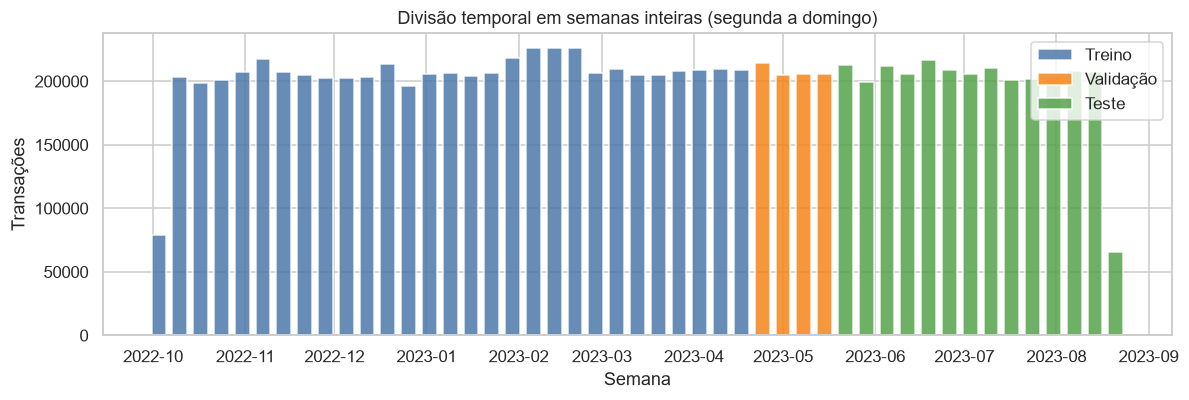

In [3]:
# Linha do tempo semanal dos três cortes
part = np.where(data.train, "Treino", np.where(data.validation, "Validação", "Teste"))
timeline = (
    pd.DataFrame({"week": truth["week"], "part": part, "y": truth["y"]})
    .groupby(["week", "part"], as_index=False)
    .agg(transacoes=("y", "size"), lavagens=("y", lambda s: (s == 1).sum()))
    .sort_values("week")
)

fig, ax = plt.subplots(figsize=(11, 3.8))
palette = {"Treino": "#4C78A8", "Validação": "#F58518", "Teste": "#54A24B"}
for p, grp in timeline.groupby("part", sort=False):
    ax.bar(grp["week"], grp["transacoes"], width=5, color=palette[p], alpha=0.85, label=p)
ax.set_title("Divisão temporal em semanas inteiras (segunda a domingo)")
ax.set_xlabel("Semana")
ax.set_ylabel("Transações")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Comparação de abordagens (registro de experimentação)

Conforme documentado em `docs/model.md`, o LightGBM oficial foi escolhido após comparar 5 abordagens
na mesma régua de avaliação (PR-AUC no teste e recall de contas lavadoras numa fila semanal de 300
contas):

| Modelo | PR-AUC no teste | Fila de 300: recall |
|---|---:|---:|
| Regras de cenário | 0,002 | 2,4% |
| Isolation Forest sozinho | 0,005 | 2,9% |
| Regressão logística | 0,635 | 80,9% |
| GRU (rede neural sequencial) | 0,887 | 96,3% |
| **LightGBM (oficial)** | **0,896** | **96,5%** |


## 3. Avaliação do modelo oficial (`models/lightgbm_v1`)

Carregamos o modelo treinado (`python -m fraudradar.model train`, ~3 min no SAML-D completo) via
`load_model()` e medimos as métricas no período de teste (`2023-05-22` a `2023-08-23`), conferindo os
números da ficha oficial `models/lightgbm_v1.json` e de `docs/model.md`.


In [4]:
booster, card = load_model()
score = booster.predict(data.x[card["features"]])

metrics, by_typology = evaluate(score, data, truth)
queue_table = queue_with_cut(score, data, truth, targets=(0.99, 0.98, 0.97, 0.95))

print(f"Modelo carregado: {card['file']} ({card['trees']} árvores)")
print(f"PR-AUC validação / teste: {metrics['pr_auc_validation']:.3f} / {metrics['pr_auc']:.3f}")
print(
    f"Recall @ 0,13% FPR: {metrics['recall_at_fpr']:.1%} "
    f"(sem atalhos: {metrics['recall_at_fpr_no_shortcut']:.1%}, "
    f"contas novas: {metrics['recall_at_fpr_new_accounts']:.1%})"
)
print(
    f"F1 por transação: {metrics['f1']:.3f} "
    f"(precisão {metrics['f1_precision']:.1%}, recall {metrics['f1_recall']:.1%})"
)
print(
    f"Fila fixa de 300: recall {metrics['queue_recall']:.1%}, "
    f"precisão {metrics['queue_precision']:.1%}"
)

display(queue_table.round(4))

Modelo carregado: lightgbm_v1.txt (1190 árvores)
PR-AUC validação / teste: 0.882 / 0.896
Recall @ 0,13% FPR: 89.7% (sem atalhos: 91.3%, contas novas: 96.0%)
F1 por transação: 0.890 (precisão 97.0%, recall 82.1%)
Fila fixa de 300: recall 96.5%, precisão 74.8%


,target,cut,recall,precision,f1,accounts_per_week,innocents_per_week
0,NaN,-inf,0.9650,0.7476,0.8425,300.0000,75.7143
1,0.99,0.0052,0.9650,0.7476,0.8425,300.0000,75.7143
2,0.98,0.0259,0.9650,0.7618,0.8514,294.4286,70.1429
3,0.97,0.0508,0.9650,0.7799,0.8626,287.5714,63.2857
4,0.95,0.4230,0.9508,0.9901,0.9701,223.2143,2.2143


## 4. Curva Precision-Recall e comportamento semanal da fila com corte

Com o corte de fila escolhido na validação (`queue_cut = 0,4230`), a fila mantém **95,1%** de recall
por conta com **99,0%** de precisão e apenas **2,2 contas inocentes por semana** (~223 contas/semana
na fila).


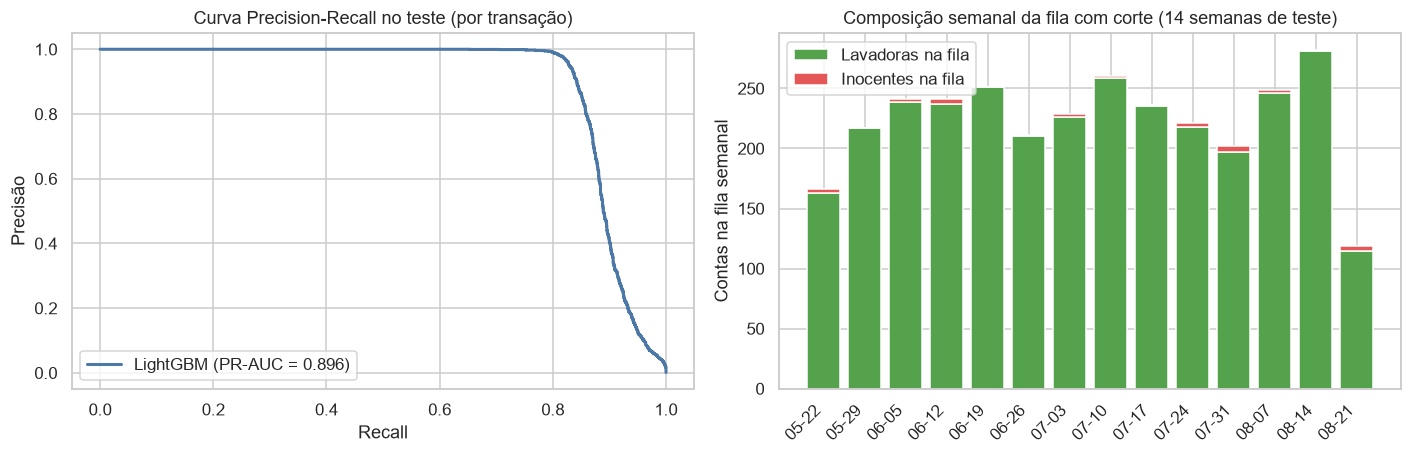

In [5]:
y_te = truth["y"].to_numpy()[data.test]
s_te = score[data.test]
prec, rec, _ = precision_recall_curve(y_te, s_te)

# Desempenho semanal da fila com corte oficial
week_te = truth["week"].to_numpy()[data.test]
acc_te = account_weeks(week_te, data.sender[data.test], data.receiver[data.test], s_te, y_te)
above = acc_te[acc_te["score"] >= card["queue_cut"]]
q_te = (
    above.sort_values("score", ascending=False, kind="stable")
    .groupby(level="week")
    .head(card["queue_size"])
)
weekly_q = q_te.groupby(level="week").agg(
    contas_fila=("y", "size"),
    lavadoras_fila=("y", "sum"),
    inocentes_fila=("y", lambda s: int((s == 0).sum())),
)
weekly_q["lavadoras_total"] = acc_te.groupby(level="week")["y"].sum()
weekly_q["recall_pct"] = weekly_q["lavadoras_fila"] / weekly_q["lavadoras_total"] * 100
weekly_q["precisao_pct"] = weekly_q["lavadoras_fila"] / weekly_q["contas_fila"] * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(rec, prec, color="#4C78A8", lw=2, label=f"LightGBM (PR-AUC = {metrics['pr_auc']:.3f})")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precisão")
axes[0].set_title("Curva Precision-Recall no teste (por transação)")
axes[0].legend()

x_idx = np.arange(len(weekly_q))
axes[1].bar(x_idx, weekly_q["lavadoras_fila"], color="#54A24B", label="Lavadoras na fila")
axes[1].bar(
    x_idx,
    weekly_q["inocentes_fila"],
    bottom=weekly_q["lavadoras_fila"],
    color="#E45756",
    label="Inocentes na fila",
)
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels([d.strftime("%m-%d") for d in weekly_q.index], rotation=45, ha="right")
axes[1].set_ylabel("Contas na fila semanal")
axes[1].set_title("Composição semanal da fila com corte (14 semanas de teste)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Recall por tipologia e análise de falso positivo por grupo

O modelo atinge **97%–100%** de recall na maioria das tipologias em rede e estruturação, porém
apresenta menor sensibilidade nas tipologias em espécie (`cash_withdrawal` 59,5%, `smurfing` 74,5%,
`deposit_send` 78,1%) e taxa de falso positivo mais alta em depósitos em espécie normais (2,8% vs
0,02% em cheque) — limitações explicitamente declaradas à banca.


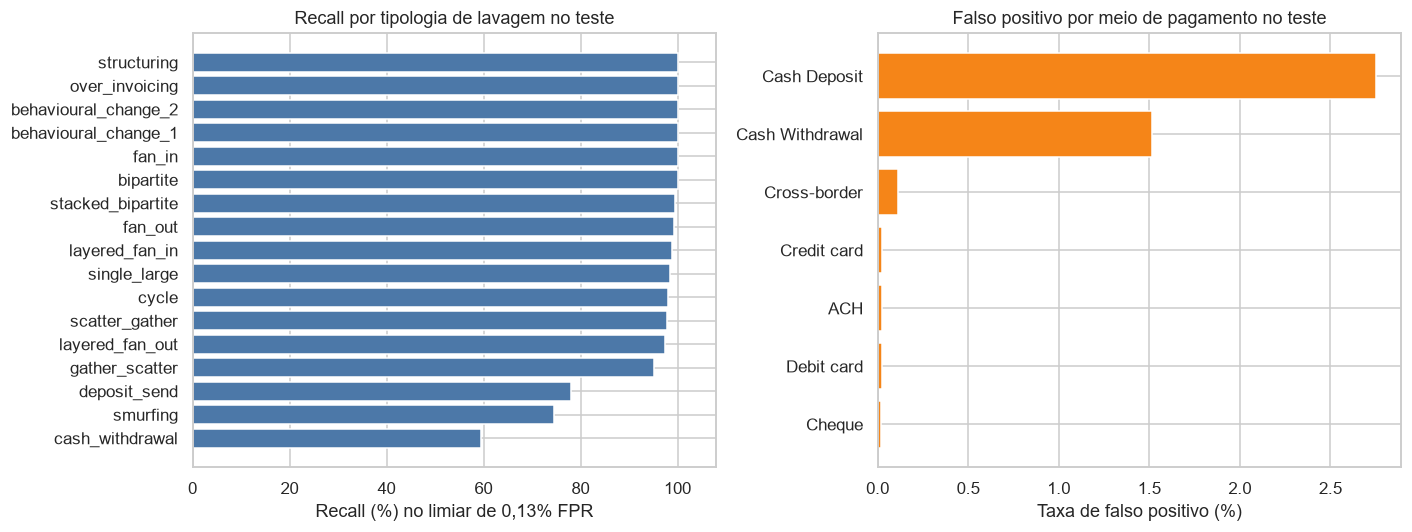

In [6]:
typ_df = by_typology.sort_values(ascending=True).mul(100).rename("recall_pct").reset_index()
typ_df.columns = ["typology", "recall_pct"]
bias = false_positive_by_group(score, data, truth)
pay_bias = bias[bias["group"] == "payment_type"].sort_values("fpr", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(typ_df["typology"], typ_df["recall_pct"], color="#4C78A8")
axes[0].set_xlabel("Recall (%) no limiar de 0,13% FPR")
axes[0].set_title("Recall por tipologia de lavagem no teste")
axes[0].set_xlim(0, 108)

axes[1].barh(pay_bias["value"].astype(str), pay_bias["fpr"] * 100, color="#F58518")
axes[1].set_xlabel("Taxa de falso positivo (%)")
axes[1].set_title("Falso positivo por meio de pagamento no teste")

plt.tight_layout()
plt.show()

## 6. Importância das variáveis, explicações individuais (`explain`) e segmentos (`assign_segments`)

Cada alerta exibido ao analista traz as 5 variáveis com maior contribuição positiva em log-odds
(`pred_contrib`, equivalente ao SHAP exato em árvores). Abaixo exibimos a importância global
(ganho) e exemplos reais explicados da fila de teste, além dos 8 segmentos K-Means das contas.


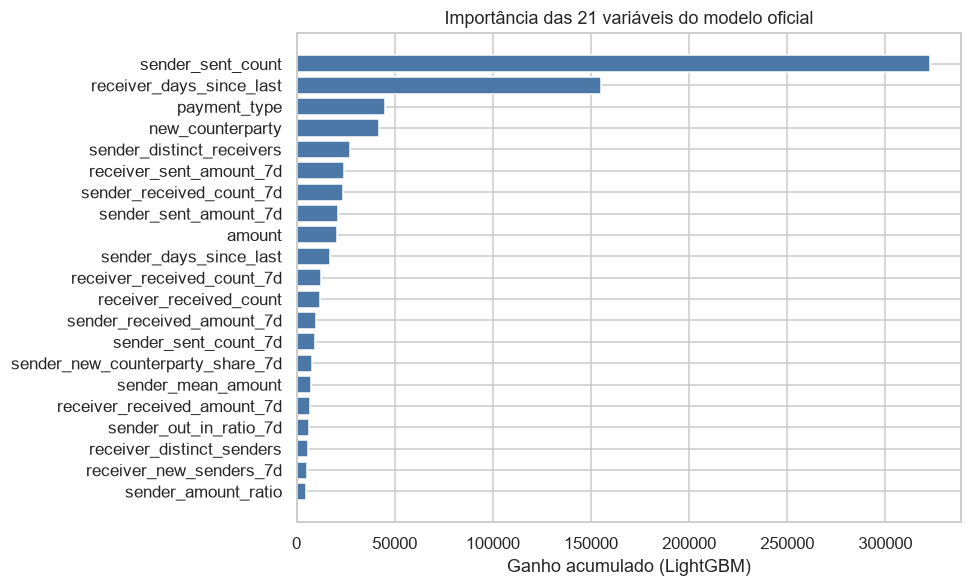

In [7]:
imp = pd.DataFrame(
    {
        "feature": card["features"],
        "gain": booster.feature_importance(importance_type="gain"),
    }
).sort_values("gain", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(imp["feature"], imp["gain"], color="#4C78A8")
ax.set_xlabel("Ganho acumulado (LightGBM)")
ax.set_title("Importância das 21 variáveis do modelo oficial")
plt.tight_layout()
plt.show()

In [8]:
# Exemplos de explicação por contribuição (SHAP em log-odds) na primeira semana de teste
first_test_week = np.datetime64(pd.Timestamp(OFFICIAL_SPLIT.train_end) + pd.Timedelta(days=1))
mask_w = data.test & (truth["week"].to_numpy() == first_test_week)
top_indices = np.flatnonzero(mask_w)[np.argsort(-score[mask_w])[:5]]
explanations = explain(booster, data.x[card["features"]].iloc[top_indices], top=3)

sample_rows = []
for idx, reasons in zip(top_indices, explanations, strict=True):
    sample_rows.append(
        {
            "score": round(float(score[idx]), 4),
            "lavagem_real": int(truth["y"].iat[idx]),
            "tipologia": truth["typology"].iat[idx],
            "meio": str(data.x["payment_type"].iat[idx]),
            "valor_gbp": round(float(data.x["amount"].iat[idx]), 2),
            "top_3_contribuicoes": "; ".join(
                f"{r['feature']} ({r['contribution']:+.2f})" for r in reasons
            ),
        }
    )
display(pd.DataFrame(sample_rows))

# Segmentos K-Means nas 12 semanas anteriores ao teste
until = pd.Timestamp(card["train_end"]) + pd.Timedelta(days=1)
profiles = account_profile(tx, until=until)
seg = assign_segments(profiles, card["segments"])
sil = {k: round(v, 3) for k, v in card["segments"]["silhouette"].items()}
print("Silhuetas K-Means (k=3..8):", sil)
display(seg.value_counts().sort_index().rename("contas").to_frame())

,score,lavagem_real,tipologia,meio,valor_gbp,top_3_contribuicoes
0,1.0000,1,fan_in,ACH,8049.74,new_counterparty (+8.22); receiver_days_since_...
1,1.0000,1,layered_fan_in,Debit card,16257.95,new_counterparty (+8.77); receiver_days_since_...
2,1.0000,1,fan_in,ACH,5038.16,new_counterparty (+7.87); receiver_days_since_...
3,1.0000,1,behavioural_change_2,Cross-border,1741.53,new_counterparty (+4.33); sender_received_coun...
4,0.9999,1,cycle,ACH,62867.34,new_counterparty (+8.02); receiver_days_since_...


Silhuetas K-Means (k=3..8): {'3': 0.662, '4': 0.651, '5': 0.658, '6': 0.654, '7': 0.659, '8': 0.677}


,contas
segment,
0,311113
1,56036
2,22395
3,13081
4,3995
5,29660
6,2708
7,8659


## 7. Limitações declaradas à banca

1. **Dataset sintético:** os números são altos no SAML-D, por isso a comparação honesta é feita
   contra as regras determinísticas no mesmo dado (fila de 300 com **2,4%** de recall vs **96,5%**
   do LightGBM).
2. **Operações em espécie:** menor recall (`cash_withdrawal` 59,5%, `smurfing` 74,5%) e maior falso
   positivo em depósitos em espécie normais (2,8% vs 0,02% em cheque).
3. **Score não calibrado:** o valor na escala de 0 a 100 ordena a fila de risco e não representa
   probabilidade calibrada de lavagem.
4. **Semente única:** cada experimento rodou com uma semente fixa de reprodutibilidade.
